<a href="https://colab.research.google.com/github/pika97/Predictive-Maintenence---Machine-Failure-Prediction/blob/main/MLmodel_for_machiner_failure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The Bussiness Problem: The manufacturing company that operates hundreds of machines.

Machines sometimes fail unexpectedly, causing:
- Production delays.
- Increased maintenance costs.
- Equipment downtime.
- Product quality issues.
- Potential safety risks.

Predictive Maintenance: Machine Failure Prediction Using Machine Learning

Project Overview
This project focuses on developing a supervised machine learning model to predict machine failures using industrial operating data. The objective is to identify potential equipment failures based on parameters such as air temperature, process temperature, rotational speed, torque and tool wear.

I chose predictive maintenance because unexpected equipment failures can lead to production downtime, increased maintenance costs and operational inefficiencies. With my background in Biomedical Engineering and experience in quality investigations, I wanted to explore how machine learning can be applied to equipment reliability, failure prediction and preventive decision-making.

I selected supervised learning because the AI4I 2020 dataset contains labelled historical observations, including a 'Machine Failure' target indicating whether a failure occurred (0 = No Failure, 1 = Failure). This allows a classification model to learn patterns from labelled data and predict failures in previously unseen observations.

Python Libraries and Methods Used
- Python: Main programming language.
- Pandas & NumPy: Data loading, exploration, cleaning and numerical operations.
- Matplotlib: Exploratory data analysis and data visualisation.
- Scikit-learn: Data preprocessing, feature engineering, model training and evaluation.
- Data Cleaning: Missing-value handling, duplicate checks and outlier investigation.
- Preprocessing: Median imputation, feature scaling using StandardScaler and categorical encoding using OneHotEncoder.
- Data Splitting: 80% training and 20% testing.
- Machine Learning Models: Logistic Regression and Random Forest Classifier.
- Model Evaluation: Accuracy, Precision, Recall, F1-score, ROC-AUC, PR-AUC and Confusion Matrix.

Project Objective
To build, evaluate and compare supervised classification models, identify important machine operating parameters associated with failures, and explore how predictive analytics can support proactive equipment maintenance.

Task as an Ai/ML Engineer is to build a machine learning model that predicts weather a machine is likely to experience a failure.

Data shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Duplicate_Product_id's:
 0

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicated values:
 0


,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


Failure rate: 3.39%
A model that always predicts no failure would be 96.61% accurate.


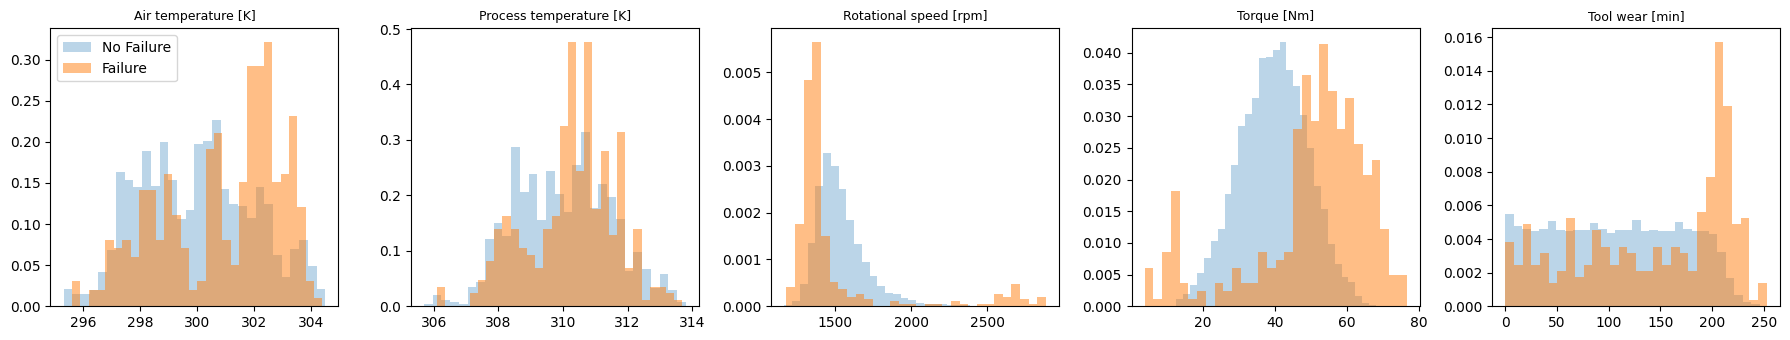


Train shape:
 (8000, 6) (8000,)

Test shape:
 (2000, 6) (2000,) | failures in test: 68


,precision,recall,f1,pr_auc,roc_auc
Dummy,0.000,0.000,0.000,0.034,0.500
Logistic Regression,0.137,0.804,0.235,0.441,0.897
Random Forest,0.924,0.391,0.548,0.755,0.969
HistGradient Boosting,0.672,0.768,0.716,0.793,0.970


precision  recall     f1  pr_auc  \
Baseline           Dummy                      0.000   0.000  0.000   0.034   
                   Logistic Regression        0.137   0.804  0.235   0.441   
                   Random Forest              0.924   0.391  0.548   0.755   
                   HistGradient Boosting      0.672   0.768  0.716   0.793   
Feature Engineered Dummy                      0.000   0.000  0.000   0.034   
                   Logistic Regression        0.162   0.841  0.271   0.459   
                   Random Forest              0.980   0.749  0.848   0.895   
                   HistGradient Boosting      0.851   0.819  0.834   0.878   

                                          roc_auc  
Baseline           Dummy                    0.500  
                   Logistic Regression      0.897  
                   Random Forest            0.969  
                   HistGradient Boosting    0.970  
Feature Engineered Dummy                    0.500  
                   Logistic Regression      0.923  
                   Random Forest            0.980  
                   HistGradient Boosting    0.974

Best model: Random Forest
Best threshold: 0.330 (default would be 0.5)


,precision,recall,f1,pr_auc,roc_auc
threshold 0.5,0.963,0.765,0.852,0.874,0.968
tuned(0.33),0.933,0.824,0.875,0.874,0.968


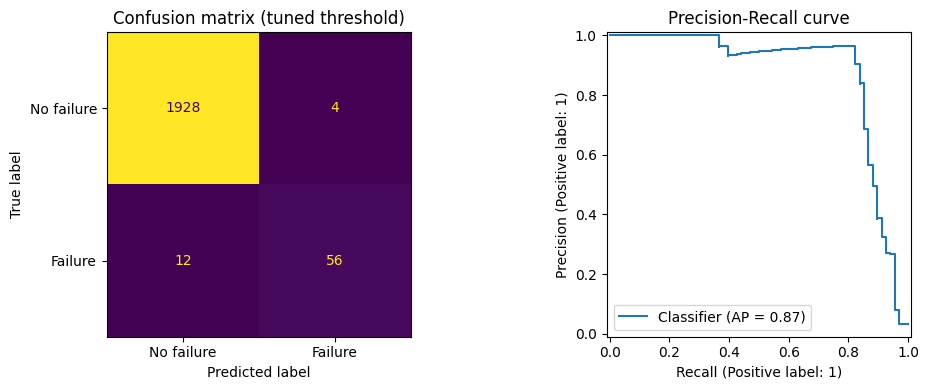

In [ ]:
# data collection and loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

# splitting and validating
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, cross_val_predict

# pre-processing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier

# evaluation metrics
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, precision_recall_curve
)

# feature importance
from sklearn.inspection import permutation_importance

# warning handling
from sklearn.exceptions import UndefinedMetricWarning
from pathlib import Path

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

RANDOM_STATE = 42

# Load and read the dataset
d_f = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ai4i+2020+predictive+maintenance+dataset.zip')
d_f.columns = d_f.columns.str.strip()
print("Data shape:", d_f.shape)
display(d_f.head())

# Data exploration and analysis (EDA)
Product_id = d_f['Product ID'].duplicated().sum()
print("\nDuplicate_Product_id's:\n", Product_id)
print("\nMissing values:\n", d_f.isnull().sum())
print("\nDuplicated values:\n", d_f.duplicated().sum())
display(d_f.dtypes)

failure_rate = d_f["Machine failure"].mean()
print(f"Failure rate: {failure_rate:.2%}")
print(f"A model that always predicts no failure would be {1 - failure_rate:.2%} accurate.")

process_parameters_col = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, process_parameters_col):
    ax.hist(d_f.loc[d_f["Machine failure"] == 0, col], bins=30, alpha=0.6, density=True, label="No Failure")
    ax.hist(d_f.loc[d_f["Machine failure"] == 1, col], bins=30, alpha=0.5, density=True, label="Failure")
    ax.set_title(col, fontsize=9)
axes[0].legend()
plt.tight_layout()
plt.show()

# separate X and y features
X = d_f[["Type"] + process_parameters_col]
y = d_f["Machine failure"]

# splitting the data in training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("\nTrain shape:\n", X_train.shape, y_train.shape)
print("\nTest shape:\n", X_test.shape, y_test.shape, f"| failures in test: {y_test.sum()}")

# pipeline
def make_preprocessor(numeric_cols):
    return ColumnTransformer([
        ("type", OneHotEncoder(), ["Type"]),
        ("num", StandardScaler(), numeric_cols),
    ])

nums_col = process_parameters_col

models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=1000, random_state=42, class_weight="balanced", n_jobs=-1),
    "HistGradient Boosting": HistGradientBoostingClassifier(random_state=42, class_weight="balanced")
}

pipelines = {
    name: Pipeline([("prep", make_preprocessor(nums_col)), ("model", m)])
    for name, m in models.items()
}

# compare models with cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc"
}

rows = {}
for name, pipe in pipelines.items():
    res_cv = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows[name] = {k.replace("test_", ""): v.mean() for k, v in res_cv.items() if k.startswith("test_")}

res_cv_table = pd.DataFrame(rows).T.round(3)
display(res_cv_table)

# adding Features
def add_features(data):
    out = data.copy()
    out["Temp difference [K]"] = out["Process temperature [K]"] - out["Air temperature [K]"]
    out["Power [W]"] = out["Torque [Nm]"] * (out["Rotational speed [rpm]"] * 2 * np.pi / 60)
    out["Wear x Torque"] = out["Tool wear [min]"] * out["Torque [Nm]"]
    return out

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
nums_col_fe = process_parameters_col + ["Temp difference [K]", "Power [W]", "Wear x Torque"]

pipelines_fe = {
    name: Pipeline([("prep", make_preprocessor(nums_col_fe)), ("model", m)])
    for name, m in models.items()
}

rows_fe = {}
for name, pipe in pipelines_fe.items():
    res_cv = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows_fe[name] = {k.replace("test_", ""): v.mean() for k, v in res_cv.items() if k.startswith("test_")}

res_cv_table_fe = pd.DataFrame(rows_fe).T.round(3)
display(pd.concat([res_cv_table, res_cv_table_fe], keys=['Baseline', 'Feature Engineered']))

# fine-tuning
best_name = res_cv_table_fe["pr_auc"].idxmax()
print("Best model:", best_name)
best_pipe = pipelines_fe[best_name]

oof_proba = cross_val_predict(best_pipe, X_train_fe, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)

# Avoid division by zero
f2 = 5 * prec * rec / (4 * prec + rec + 1e-9)
best_thr = thr[np.argmax(f2[:-1])]  # thr has length len(prec) - 1
print(f"Best threshold: {best_thr:.3f} (default would be 0.5)")

# evaluation on the test data
best_pipe.fit(X_train_fe, y_train)
proba = best_pipe.predict_proba(X_test_fe)[:, 1]

def report(threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred)
    }

final = pd.DataFrame({"threshold 0.5": report(0.5), f"tuned({best_thr:.2f})": report(best_thr)}).T.round(3)
final["pr_auc"] = round(average_precision_score(y_test, proba), 3)
final["roc_auc"] = round(roc_auc_score(y_test, proba), 3)
display(final)

# using the confusion matrix to see the number of false positives and false negatives
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pred_tuned = (proba >= best_thr).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_tuned),
                       display_labels=["No failure", "Failure"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (tuned threshold)")

PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[1])
axes[1].set_title("Precision-Recall curve")
plt.tight_layout()
plt.show()